In [2]:
from auxillaryFunctions import *
from scipy.signal import welch

np.random.seed(0)

build_dir,configType = "build", "Release" #"Debug" Release ##NOTE: make sure your are using correct version
moduleDir = os.path.join(build_dir, configType)
if moduleDir not in sys.path:
    sys.path.append(moduleDir)

import cathalTest

def solveSystemCpp(ac,TS,runTime,samplingInterval=2,stimInfoSpikes={},stimInfoCurrents = {}, 
                   recordingKeys = ["voltages","calciumVals","netCurrent","current"],singleThread=False):
    nIterations = int(runTime/TS)
    nSamples = int(np.ceil(nIterations/samplingInterval))
    spikeStimTimes,spikeStimNeurons = genSpikeStimArrays(stimInfoSpikes)
    ac["spikeStimTimes"] = spikeStimTimes
    ac["spikeStimNeurons"] = spikeStimNeurons

    biasStimTimes,biasStimSegments,biasStimValues = genBiasStimArrays(stimInfoCurrents)
    ac["biasStimTimes"] = biasStimTimes
    ac["biasStimSegments"] = biasStimSegments
    ac["biasStimValues"] = biasStimValues
    ac["performanceStats"] = np.zeros(8,dtype=np.float32)


    recordingData = {}
    for key in recordingKeys:
        shape = [nSamples] + list(ac[key].shape)
        recordingData[key] = np.zeros(shape,dtype=np.float32) #np.ascontiguousarray

    tv = np.linspace(0,runTime,nSamples)

    if singleThread:
        cathalTest.solveNeuralSystemSingleThread(ac,recordingData,TS,nIterations,samplingInterval)
    else:
        cathalTest.solveNeuralSystem(ac,recordingData,TS,nIterations,samplingInterval)
    
    #trackPerfOverTime(ac)
    recordingData["time"] = tv
    return recordingData

def getCorrectSpikerOutput(data):
    #"spikes" as recorded can last for more than one iteration because its just Vm>0 
    deriv = np.diff(data["spikerOutput"],axis=0)>0
    deriv = np.pad(deriv, ((1, 0), (0, 0)), mode='constant')
    return deriv

def getPopSpikeTrains(simData,data):
    correctOp = getCorrectSpikerOutput(data)

    spikeTimes = [[] for i in range(data["spikerOutput"].shape[1])]
    for timeInd,neurInd in zip(*np.where(correctOp)):
        spikeTimes[neurInd].append(float(data["time"][timeInd]))

    indices = {}
    for popName,popDict in  simData["indexMaps"]["neuronPopToSpikerMap"].items():
        indices[popName] = list(popDict.values())

    spikeTimeDict = {}
    for pop,inds in indices.items():
        spikeTimeDict[pop] = [spikeTimes[i] for i in inds]

    return spikeTimeDict


In [27]:
np.random.seed(0)

STNchannels = np.load(r"tools\translatedSTNchannels2.npy",allow_pickle=True).item()
GPechannels = np.load(r"tools\translatedGPechannels2.npy",allow_pickle=True).item()


STNbias = -2.05
GPeBias = -0.55

TS = 0.04
runTime = 3*1000

CTXrate,GPerate = 3.3,1 #3.3,2.1

bestRes = [0.06,0.025,0.01,0.005,0.27115]
wCTXToSTN =  bestRes[0] 
wSTNToGPe =  bestRes[1]
wGPeToSTN = bestRes[2]
wGPeToGPe = bestRes[3]
wMSNToGPe =  bestRes[4]

#NOTE: for investigating plasticity we want to set up a little simulation 
# with a couple of pre-synaptic CTX neurons and a post synaptic STN neuron
#Then we adjust parameters until we get something stable in the single cell
#Then we try with a population and adjust until we get something stable 
# Need to do this for excitatory and inhibitory synapses, lets start with STN

coupling,nSegments = 0.25,1 #try with one segment
STNDendriteMap = [(i+1,0,coupling) for i in range(nSegments)]
STNDendriteInfo = [{"channels":STNchannels,"bias":STNbias,"CaEquilibriumVal":0,
                            "CaRemovalRate":2} for _ in range(nSegments)]
STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias,denderiteInfo=STNDendriteInfo,dendriteMap=STNDendriteMap) for i in range(1)]

nCTX = nGPe = 1
CTXSpikers = [Spiker(i,"CTX","excitatory",CTXrate,TS) for i in range(nCTX)]
GPeSpikers = [Spiker(i,"GPe","inhibitory",GPerate,TS) for i in range(nGPe)]

neuronDict = {"STN":STNNeurons}
spikerDict = {"CTX":CTXSpikers,"GPe":GPeSpikers}

seg = 1 #target the first dendritic segment, not the soma (though we can try that)
CSEL = [[i,0,seg] for i in range(nCTX)]
GSEL = [[i,0,seg] for i in range(nGPe)]

CTXToSTNSynapses = createSynapses(CTXSpikers,STNNeurons,None,wCTXToSTN,0.2,TS,CSEL)
GPeToSTNSynapses = createSynapses(GPeSpikers,STNNeurons,None,wGPeToSTN,4,TS,GSEL)

synapseDict = {"CTXToSTN":CTXToSTNSynapses,"GPeToSTN":GPeToSTNSynapses}

simData = genSimData(neuronDict,spikerDict,synapseDict,TS)
print(f"Total number of channels {simData['nChannels']}")

Total number of channels 18


Elapsed time in seconds: 0.1525638
STN 3.0
CTX 2.333333333333333
GPe 1.0


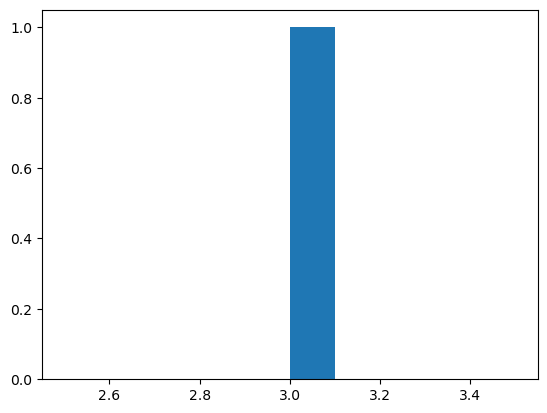

In [28]:
stimInfoSpikes,stimInfoCurrents = {},{}
simDataCpp = deepcopy(simData)
simDataCpp["debugRecording"] = np.zeros_like(simDataCpp["current"])
dataCpp = solveSystemCpp(simDataCpp,TS,runTime,samplingInterval=1,stimInfoSpikes=stimInfoSpikes,
                        recordingKeys =["spikerOutput","voltages","calciumVals"],singleThread=True)

spikeTimeDict = getPopSpikeTrains(simDataCpp,dataCpp)

firingRates = {}
for pop,data in spikeTimeDict.items():
    firingRates[pop] = (1e3/runTime)* np.array([len(x) for x in data])

plt.hist(firingRates["STN"]);
for pop,rates in firingRates.items():
    print(pop,np.mean(rates))

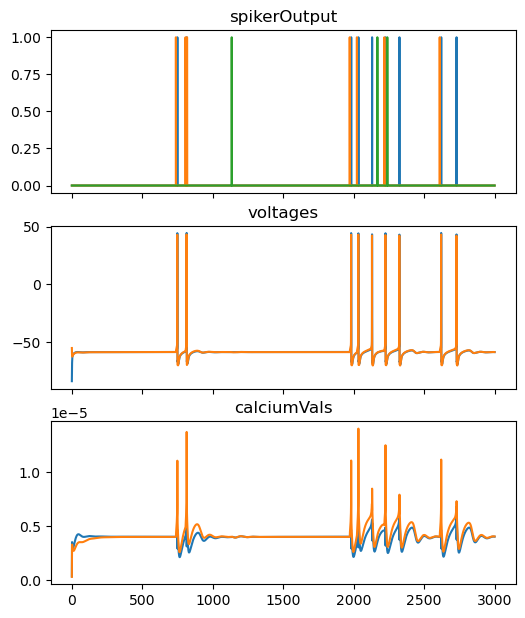

In [29]:
#TODO: better plotting
keysToPlot = ["spikerOutput","voltages","calciumVals","time"]
standardPlot({key:dataCpp[key] for key in keysToPlot})

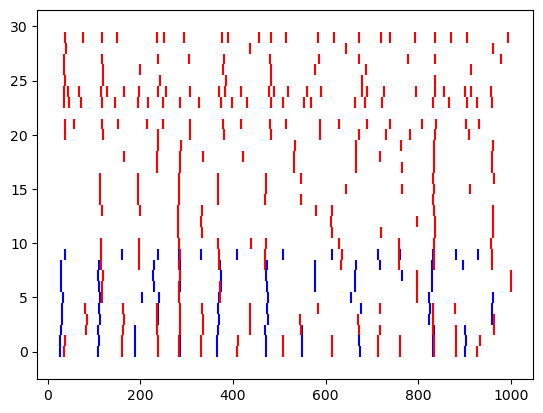

In [5]:


spikeTimeDict = getPopSpikeTrains(simDataCpp,dataCpp)
fig,ax = plt.subplots(1,1)
ax.eventplot(spikeTimeDict["STN"],color="b");
ax.eventplot(spikeTimeDict["GPe"],color="r");

: 

In [20]:
frs

{'STN': 6.72, 'GPe': 7.56, 'CTX': 3.28, 'MSN': 2.119666666666667}

In [ ]:
#TODO: Dec 1st 2025. 
#Next is to get firing rates, and instantaneuos firing rate plots
#Then update the CPP code
#Then tune the STN-GPe net

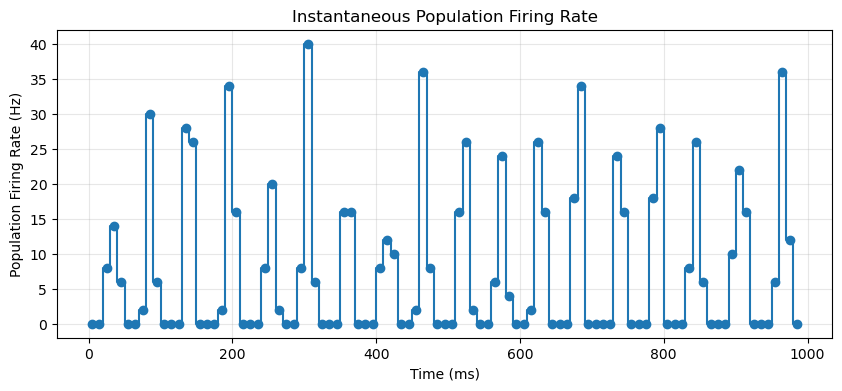

In [ ]:
stimInfoSpikes = {}
syns = [i for i,n in enumerate(simData["name"]) if n == "AMPAR"] #"AMPAR" #GABA
#stimSynapse(stimInfoSpikes,syns,50,100,TS

runTime = 400
stimInfoCurrents = {} 

simDataPy = deepcopy(simData)
simDataPy["debugRecording"] = np.zeros_like(simDataPy["current"])

data = solveSystemStandard(simDataPy,TS,runTime,stimInfoSpikes,stimInfoCurrents,vectorized=True,nSamples=None, useTQDM=True,
                           recordingKeys = ["voltages","calciumVals","netCurrent","x","debugRecording","CaChannelCurrent","spikerOutput"])

#TODO: add spike recording to cpp side
simDataPy["spikeTrains"]; #NOTE: I dont like this philosophy of this and it sholud be removed later. Keep state and recording data separate 


In [2]:
build_dir,configType = "build", "Release" #"Debug" Release ##NOTE: make sure your are using correct version
moduleDir = os.path.join(build_dir, configType)
if moduleDir not in sys.path:
    sys.path.append(moduleDir)

import cathalTest

    
def solveSystemCpp(ac,TS,runTime,samplingInterval=2,stimInfoSpikes={},stimInfoCurrents = {}, recordingKeys = ["voltages","calciumVals","netCurrent","current"]):
    nIterations = int(runTime/TS)
    nSamples = int(np.ceil(nIterations/samplingInterval))
    spikeStimTimes,spikeStimNeurons = genSpikeStimArrays(stimInfoSpikes)
    ac["spikeStimTimes"] = spikeStimTimes
    ac["spikeStimNeurons"] = spikeStimNeurons

    biasStimTimes,biasStimSegments,biasStimValues = genBiasStimArrays(stimInfoCurrents)
    ac["biasStimTimes"] = biasStimTimes
    ac["biasStimSegments"] = biasStimSegments
    ac["biasStimValues"] = biasStimValues
    ac["performanceStats"] = np.zeros(8,dtype=np.float32)


    recordingData = {}
    for key in recordingKeys:
        shape = [nSamples] + list(ac[key].shape)
        recordingData[key] = np.zeros(shape,dtype=np.float32) #np.ascontiguousarray

    tv = np.linspace(0,runTime,nSamples)
    print("here")
    cathalTest.solveNeuralSystem(ac,recordingData,TS,nIterations,samplingInterval)

    #trackPerfOverTime(ac)

    recordingData["time"] = tv
    return recordingData



stimInfoSpikes,stimInfoCurrents = {},{}
allChannelDataCpp = deepcopy(simData)
allChannelDataCpp["debugRecording"] = np.zeros_like(simDataPy["current"])
dataCpp = solveSystemCpp(allChannelDataCpp,TS,runTime,samplingInterval=4,stimInfoSpikes=stimInfoSpikes,
                         recordingKeys = ["voltages","calciumVals","current"])



NameError: name 'simDataPy' is not defined